# Bike Sharing Demand Analysis

## 1. Project Overview

This project analyses bike-sharing demand to understand
how time, weather, seasons and working days influence
the number of bike rentals.

## 2. Objectives

- Understand the structure of the dataset.
- Identify and handle missing or inconsistent data.
- Explore patterns in bike rental demand.
- Create meaningful visualisations.
- Present actionable insights from the analysis.

In [1]:
# Import the libraries we will use

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns when viewing datasets
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load the raw dataset
df = pd.read_csv("../data/raw/hour.csv")

# Display the first five rows
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [6]:
df.shape

(17379, 17)

In [8]:
df.columns.tolist()

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'hr',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt']

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [12]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [14]:
df.duplicated().sum()

0

In [16]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [18]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [20]:
# Convert dteday into datetime format
df["dteday"] = pd.to_datetime(df["dteday"])

# Check the data type
print(df["dteday"].dtype)

datetime64[ns]


In [22]:
# Check rental count consistency
df["calculated_total"] = df["casual"] + df["registered"]

inconsistent_rows = df[
    df["calculated_total"] != df["cnt"]
]

print("Inconsistent records:", len(inconsistent_rows))

Inconsistent records: 0


In [24]:
df[["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]].describe()

,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [26]:
df.drop(columns=["calculated_total"], inplace=True)

# 3. Exploratory Data Analysis (EDA)

In this section, we explore bike rental demand
to identify patterns across hours, weekdays,
seasons and weather conditions.

In [29]:
# Create a working copy of our dataset
df_clean = df.copy()

# Check the dimensions
df_clean.shape

(17379, 17)

In [31]:
# Calculate average bike rentals for each hour
hourly_demand = df_clean.groupby("hr")["cnt"].mean()

# Display the results
hourly_demand

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

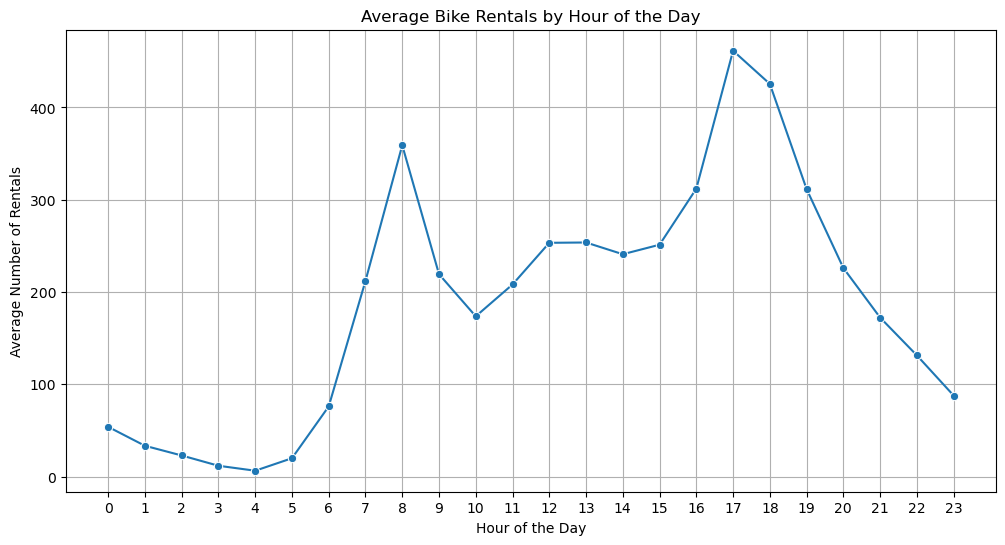

In [33]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rentals by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")

plt.xticks(range(0, 24))
plt.grid(True)

plt.show()

### Insight 1: Hourly Bike Rental Patterns

Bike rental demand varies significantly throughout
the day.

The highest average demand occurs around 5 PM,
followed by a morning peak around 8 AM.

Rental activity is lowest during the early morning,
particularly around 4 AM.

The morning and evening peaks may indicate commuting
patterns, which will be investigated further by
comparing working days with non-working days.

In [38]:
# Group bike rentals by hour and working day
hourly_workday = (
    df_clean
    .groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

# Give the values meaningful labels
hourly_workday["day_type"] = hourly_workday["workingday"].map({
    0: "Weekend / Holiday",
    1: "Working Day"
})

# Display the first few rows
hourly_workday.head()

,hr,workingday,cnt,day_type
0,0,0,90.800000,Weekend / Holiday
1,0,1,36.786290,Working Day
2,1,0,69.508696,Weekend / Holiday
3,1,1,16.552632,Working Day
4,2,0,53.171053,Weekend / Holiday


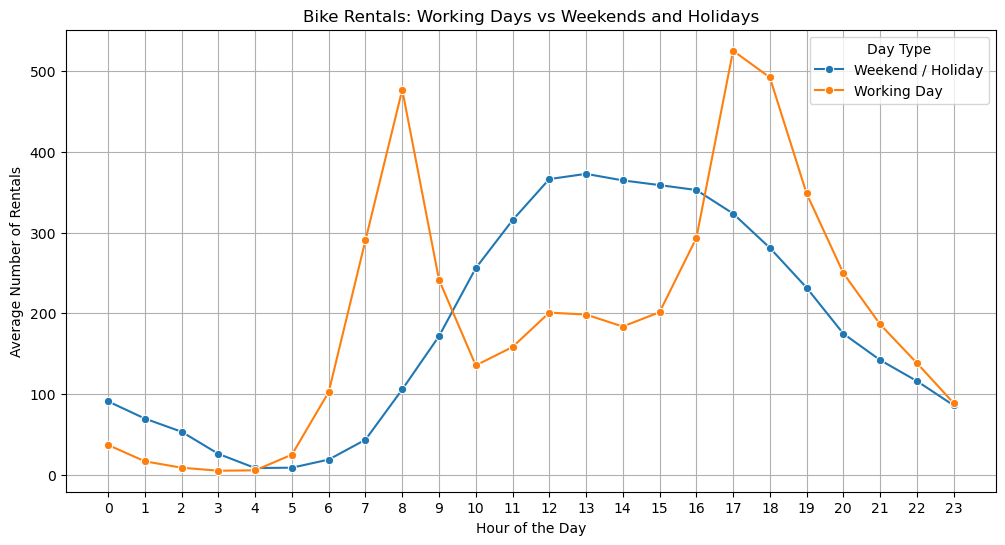

In [40]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_workday,
    x="hr",
    y="cnt",
    hue="day_type",
    marker="o"
)

plt.title("Bike Rentals: Working Days vs Weekends and Holidays")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")

plt.xticks(range(0, 24))
plt.legend(title="Day Type")
plt.grid(True)

plt.show()

### Insight 2: Working Days vs Non-Working Days

Bike rental patterns differ considerably between
working days and non-working days.

Working days show two distinct demand peaks:
8 AM and 5 PM. These patterns suggest that bikes
may be used for commuting.

In contrast, weekends and holidays show a gradual
increase in demand throughout the morning, reaching
their highest levels around 1 PM.

This suggests that leisure-related travel may
contribute more to non-working-day demand.

In [43]:
# Calculate average rentals by season
seasonal_demand = (
    df_clean
    .groupby("season")["cnt"]
    .mean()
    .reset_index()
)

# Replace numerical codes with season names
seasonal_demand["season"] = seasonal_demand["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

# Display results
seasonal_demand

,season,cnt
0,Spring,111.114569
1,Summer,208.344069
2,Fall,236.016237
3,Winter,198.868856


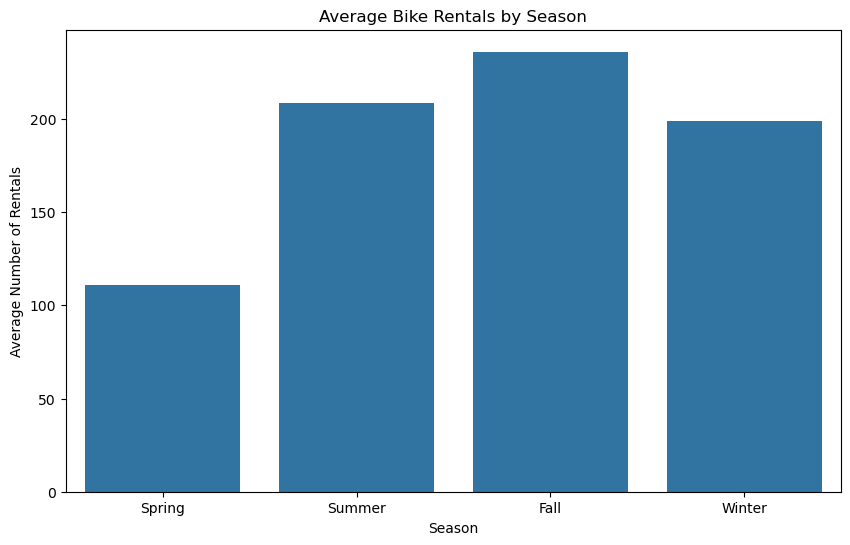

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=seasonal_demand,
    x="season",
    y="cnt"
)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Number of Rentals")

plt.show()

### Insight 3: Seasonal Bike Rental Demand

Seasonal analysis reveals noticeable differences
in bike rental demand.

Fall records the highest average hourly rentals,
followed by summer and winter.

Spring has the lowest average rental demand.

Interestingly, fall outperforms summer, suggesting
that seasonal demand may be influenced by factors
beyond temperature alone.

In [48]:
# Calculate average rentals for each weather condition
weather_demand = (
    df_clean
    .groupby("weathersit")["cnt"]
    .mean()
    .reset_index()
)

# Replace numerical codes with readable labels
weather_labels = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Weather"
}

weather_demand["weather"] = weather_demand["weathersit"].map(
    weather_labels
)

# Display results
weather_demand

,weathersit,cnt,weather
0,1,204.869272,Clear / Partly Cloudy
1,2,175.165493,Mist / Cloudy
2,3,111.579281,Light Rain / Snow
3,4,74.333333,Heavy Weather


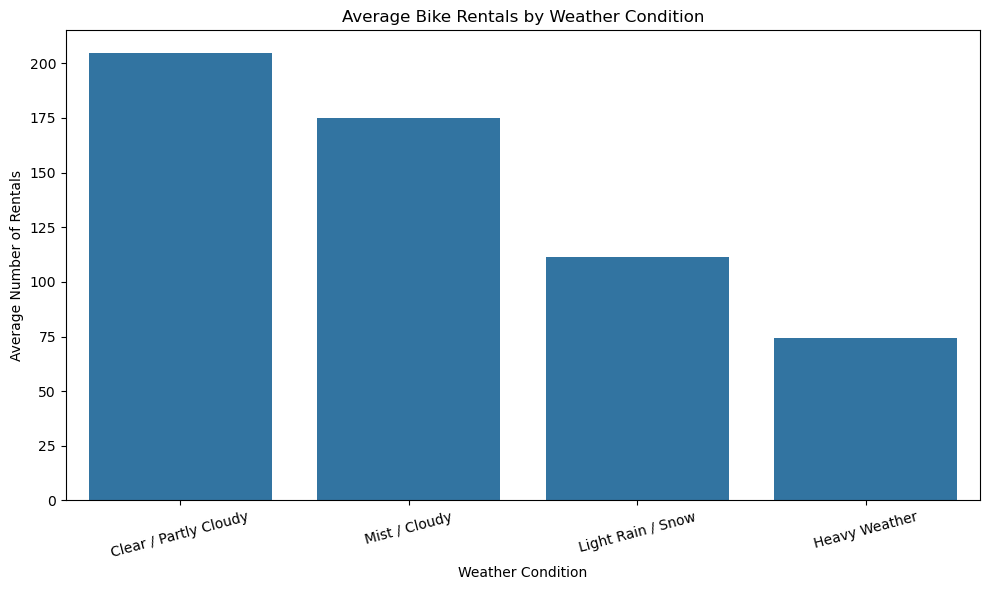

In [50]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=weather_demand,
    x="weather",
    y="cnt"
)

plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Number of Rentals")

plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

### Insight 4: Impact of Weather on Bike Rentals

Weather conditions are associated with differences
in bike rental demand.

Clear and partly cloudy conditions record the
highest average rentals, while light rain and snow
show considerably lower demand.

Heavy weather records the lowest average demand.

These findings suggest that adverse weather may
discourage bike-sharing usage. However, the number
of observations in each weather category should
also be considered when interpreting the results.

In [53]:
# Count observations for each weather condition
weather_counts = (
    df_clean["weathersit"]
    .value_counts()
    .sort_index()
)

print(weather_counts)

weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


In [55]:
# Combine average rentals and observation counts
weather_summary = (
    df_clean
    .groupby("weathersit")["cnt"]
    .agg(["mean", "count", "median"])
    .reset_index()
)

weather_summary

,weathersit,mean,count,median
0,1,204.869272,11413,159.0
1,2,175.165493,4544,133.0
2,3,111.579281,1419,63.0
3,4,74.333333,3,36.0


An important limitation is that the heavy weather
category contains only 3 observations. Therefore,
its average rental count may not represent typical
demand during severe weather conditions.

The comparison between clear, cloudy and light
precipitation conditions is supported by substantially
larger sample sizes.

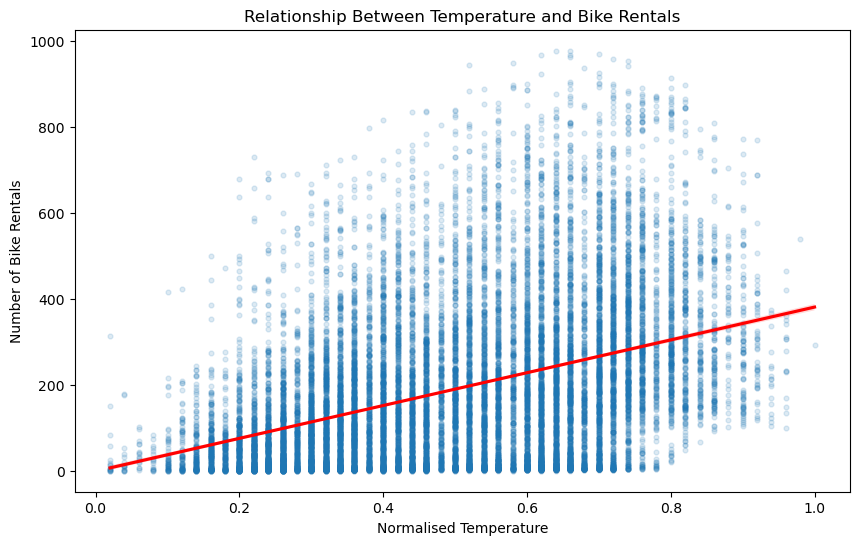

In [58]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x="temp",
    y="cnt",
    scatter_kws={"alpha": 0.15, "s": 12},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Temperature and Bike Rentals")
plt.xlabel("Normalised Temperature")
plt.ylabel("Number of Bike Rentals")

plt.show()

In [60]:
# Calculate correlation between temperature and rentals
temperature_correlation = df_clean["temp"].corr(df_clean["cnt"])

print("Temperature-Rental Correlation:", temperature_correlation)

Temperature-Rental Correlation: 0.4047722757786589


### Insight 5: Relationship Between Temperature and Bike Rentals

The analysis identifies a moderate positive correlation
between temperature and bike rental demand, with a
Pearson correlation coefficient of approximately 0.405.

The scatter plot and regression line indicate that
bike rentals generally increase as temperature rises.

However, the wide distribution of observations suggests
that temperature alone does not explain rental demand.
Other factors, including time of day, working days,
seasonality and weather conditions, may also influence
bike-sharing activity.

In [63]:
# Overall bike rental statistics

total_rentals = df_clean["cnt"].sum()

average_rentals = df_clean["cnt"].mean()

average_registered = df_clean["registered"].mean()

average_casual = df_clean["casual"].mean()

print("Total hourly rental records:", len(df_clean))
print("Total bike rentals:", total_rentals)
print("Average hourly rentals:", round(average_rentals, 2))
print("Average registered rentals:", round(average_registered, 2))
print("Average casual rentals:", round(average_casual, 2))

Total hourly rental records: 17379
Total bike rentals: 3292679
Average hourly rentals: 189.46
Average registered rentals: 153.79
Average casual rentals: 35.68


In [65]:
total_registered = df_clean["registered"].sum()
total_casual = df_clean["casual"].sum()

total_users = total_registered + total_casual

registered_percentage = (total_registered / total_users) * 100
casual_percentage = (total_casual / total_users) * 100

print("Registered users:", round(registered_percentage, 2), "%")
print("Casual users:", round(casual_percentage, 2), "%")

Registered users: 81.17 %
Casual users: 18.83 %


### Insight 6: Registered vs Casual Rental Behaviour

Registered customers account for approximately
81.17% of all bike rental events, while casual
customers account for 18.83%.

This indicates that registered customers contribute
the majority of rental activity.

From a business perspective, the bike-sharing
company could investigate opportunities to convert
casual customers into registered members.

These percentages represent rental events rather
than unique customers.

In [68]:
user_type = pd.DataFrame({
    "User Type": ["Registered", "Casual"],
    "Total Rentals": [
        total_registered,
        total_casual
    ]
})

user_type

,User Type,Total Rentals
0,Registered,2672662
1,Casual,620017


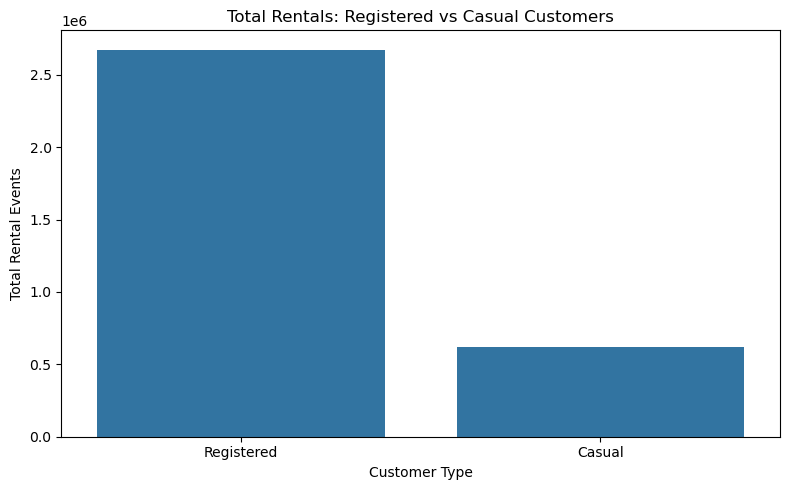

In [70]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=user_type,
    x="User Type",
    y="Total Rentals"
)

plt.title("Total Rentals: Registered vs Casual Customers")
plt.xlabel("Customer Type")
plt.ylabel("Total Rental Events")

plt.tight_layout()
plt.show()

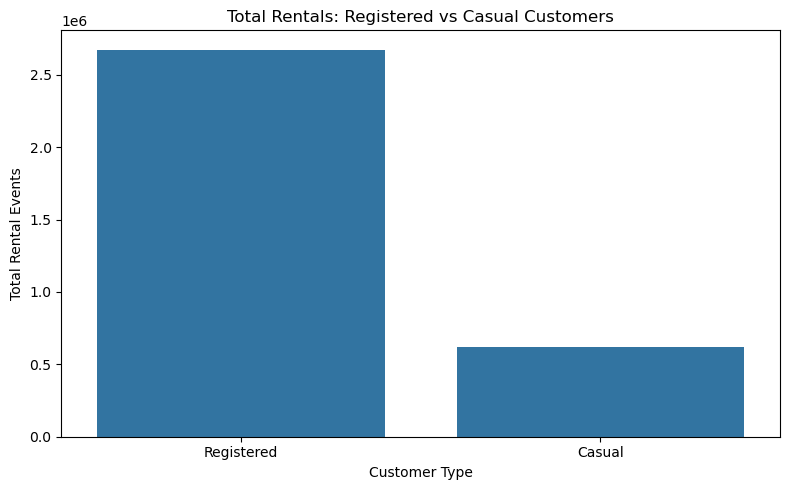

In [72]:
import os

os.makedirs("../reports/figures", exist_ok=True)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=user_type,
    x="User Type",
    y="Total Rentals"
)

plt.title("Total Rentals: Registered vs Casual Customers")
plt.xlabel("Customer Type")
plt.ylabel("Total Rental Events")

plt.tight_layout()

plt.savefig(
    "../reports/figures/user_type_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
print("Total hourly observations:", len(df_clean))

Total hourly observations: 17379


In [76]:
print("Total hourly rental records:", len(df_clean))

Total hourly rental records: 17379


In [78]:
# Export the cleaned dataset
df_clean.to_csv(
    "../data/processed/cleaned_bike_data.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [80]:
import os

file_path = "../data/processed/cleaned_bike_data.csv"

if os.path.exists(file_path):
    print("File exists!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("File not found. Check the folder path.")

File exists!
File size: 1117.49 KB
